# 01 — Exploratory Data Analysis

End-to-End MLOps · Customer Churn Project

---

**Goal:** Understand the four raw datasets before any feature engineering or modelling.

| Step | Topic |
|------|-------|
| 1 | Import libraries |
| 2 | Load `customers.csv` |
| 3 | Load `transactions.csv` |
| 4 | Load `support_interactions.csv` |
| 5 | Load `churn_labels.csv` |
| 6 | Dataset dimensions |
| 7 | Data types |
| 8 | Missing values |
| 9 | Duplicates |
| 10 | Churn distribution |
| 11 | Numerical distributions |
| 12 | Categorical distributions |
| 13 | Basic relationships with churn |
| 14 | Conclusions |

---
## 1 · Import Libraries

In [4]:
import warnings
warnings.filterwarnings("ignore")

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

# ── display settings ───────────────────────────────────────────────────────────
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", "{:.4f}".format)
sns.set_theme(style="whitegrid", palette="tab10", font_scale=1.1)
plt.rcParams["figure.dpi"] = 110

# ── paths ──────────────────────────────────────────────────────────────────────
DATA_DIR = Path("../data/raw")

print("Libraries loaded ✓")

Libraries loaded ✓


---
## 2 · Load `customers.csv`

In [5]:
customers = pd.read_csv(DATA_DIR / "customers.csv")

print(f"Shape: {customers.shape}")
customers.head()

Shape: (100000, 8)


,customer_id,age,gender,tenure_months,contract_type,payment_method,monthly_charges,total_charges
0,6e3d8adf-7f9d-4e34-bb6d-190576e545c5,56,Male,2,Month-to-month,Electronic check,28.4800,56.9600
1,740bfa1e-1d64-4ea2-9dab-6a475f51af39,69,Female,21,Month-to-month,Electronic check,110.3800,2317.9800
2,2804ba0f-7893-4f13-97be-b9411f0df4a8,46,Male,42,One year,Bank transfer,61.3100,2575.0200
3,b5986649-60d9-4470-8620-0ab0a2ae4b05,32,Female,22,Month-to-month,Bank transfer,89.6800,1972.9600
4,7fb45a3e-2e43-414a-85d0-060945ff51ba,60,Female,58,Month-to-month,Credit card,72.0100,4176.5800


---
## 3 · Load `transactions.csv`

In [6]:
transactions = pd.read_csv(
    DATA_DIR / "transactions.csv",
    parse_dates=["transaction_date"],
)

print(f"Shape: {transactions.shape}")
transactions.head()

Shape: (1000000, 5)


,transaction_id,customer_id,transaction_date,amount,payment_status
0,c37f9593-d9ec-4def-bdd7-c2c47063abcb,67944e91-1a80-4e82-9d57-28868626b25b,2023-11-24,21.5500,late
1,188b0047-07e6-4de4-b5f6-1b92d991486b,303b3259-6e62-4424-972e-ea47bc82b867,2023-02-27,91.4400,late
2,0d247f23-aaf5-4e33-8329-77ccd9207bf6,4ca498d4-c4d2-4de2-9d75-f57a257e24f0,2023-01-13,33.4000,paid
3,cf4d1483-0007-4fc0-acc1-c6e5731b4504,a3cda491-c2cf-4521-be4a-8ee98ee3c047,2024-01-15,126.0500,late
4,7604c1a0-9b9c-435e-b157-a6ff143651ef,07ff0a1e-beea-4125-876c-9c9d4b5cccad,2023-05-21,54.6000,late


---
## 4 · Load `support_interactions.csv`

In [7]:
support = pd.read_csv(
    DATA_DIR / "support_interactions.csv",
    parse_dates=["ticket_date"],
)

print(f"Shape: {support.shape}")
support.head()

Shape: (500000, 6)


,interaction_id,customer_id,ticket_date,category,resolution_days,sentiment_score
0,a7952aa5-c4a4-47ad-bcbb-894f434d4553,06c82170-849f-4dd4-b696-b7c8eccbb7d4,2023-03-09,technical,6,0.1100
1,2db2eeb3-2e78-4eff-a6fe-e3bc7005da6d,e113d81c-4992-44d5-a1d3-2d7f1b466a2b,2023-07-23,technical,13,0.8350
2,3a5e3513-37f1-466d-9bb6-9da5d4d5f16a,0a09248f-d712-4d62-93b5-39a7ecfc7dba,2023-11-21,billing,8,0.4550
3,07dc9b5e-9455-4426-ba5b-18a304827ed3,37d21158-0a26-4dfe-8dbd-2dae6b844afb,2024-02-03,billing,10,0.6030
4,a795fce2-ad78-4d30-a931-7241903b386a,90f0e2bf-dc84-4d18-8132-24bc5a3aaa82,2023-02-05,general,4,0.3190


---
## 5 · Load `churn_labels.csv`

In [8]:
labels = pd.read_csv(
    DATA_DIR / "churn_labels.csv",
    parse_dates=["label_month"],
)

print(f"Shape: {labels.shape}")
labels.head()

Shape: (100000, 3)


,customer_id,label_month,churned
0,6e3d8adf-7f9d-4e34-bb6d-190576e545c5,2024-03-01,True
1,740bfa1e-1d64-4ea2-9dab-6a475f51af39,2024-03-01,True
2,2804ba0f-7893-4f13-97be-b9411f0df4a8,2024-03-01,False
3,b5986649-60d9-4470-8620-0ab0a2ae4b05,2024-03-01,False
4,7fb45a3e-2e43-414a-85d0-060945ff51ba,2024-03-01,True


---
## 6 · Dataset Dimensions

In [9]:
dims = pd.DataFrame(
    {
        "Dataset": ["customers", "transactions", "support_interactions", "churn_labels"],
        "Rows": [
            customers.shape[0],
            transactions.shape[0],
            support.shape[0],
            labels.shape[0],
        ],
        "Columns": [
            customers.shape[1],
            transactions.shape[1],
            support.shape[1],
            labels.shape[1],
        ],
        "Unique customers": [
            customers["customer_id"].nunique(),
            transactions["customer_id"].nunique(),
            support["customer_id"].nunique(),
            labels["customer_id"].nunique(),
        ],
    }
)
dims

,Dataset,Rows,Columns,Unique customers
0,customers,100000,8,100000
1,transactions,1000000,5,99994
2,support_interactions,500000,6,99276
3,churn_labels,100000,3,100000


---
## 7 · Data Types

In [10]:
def dtype_summary(df, name):
    """Return a tidy dtype table for a single dataframe."""
    return (
        df.dtypes
        .reset_index()
        .rename(columns={"index": "column", 0: "dtype"})
        .assign(dataset=name)
        [["dataset", "column", "dtype"]]
    )

dtype_df = pd.concat(
    [
        dtype_summary(customers,    "customers"),
        dtype_summary(transactions, "transactions"),
        dtype_summary(support,      "support_interactions"),
        dtype_summary(labels,       "churn_labels"),
    ],
    ignore_index=True,
)

dtype_df

,dataset,column,dtype
0,customers,customer_id,object
1,customers,age,int64
2,customers,gender,object
3,customers,tenure_months,int64
4,customers,contract_type,object
5,customers,payment_method,object
6,customers,monthly_charges,float64
7,customers,total_charges,float64
8,transactions,transaction_id,object
9,transactions,customer_id,object


---
## 8 · Missing Values

In [11]:
def missing_summary(df, name):
    """Count and percentage of missing values per column."""
    missing = df.isnull().sum()
    pct     = missing / len(df) * 100
    return (
        pd.DataFrame({"missing": missing, "pct_missing": pct})
        .query("missing > 0")
        .assign(dataset=name)
        .reset_index()
        .rename(columns={"index": "column"})
        [["dataset", "column", "missing", "pct_missing"]]
    )

missing_df = pd.concat(
    [
        missing_summary(customers,    "customers"),
        missing_summary(transactions, "transactions"),
        missing_summary(support,      "support_interactions"),
        missing_summary(labels,       "churn_labels"),
    ],
    ignore_index=True,
)

if missing_df.empty:
    print("✅  No missing values found in any dataset.")
else:
    display(missing_df)

    fig, axes = plt.subplots(1, 4, figsize=(16, 5))
    for ax, (df, name) in zip(
        axes,
        [
            (customers,    "customers"),
            (transactions, "transactions"),
            (support,      "support_interactions"),
            (labels,       "churn_labels"),
        ],
    ):
        pct = df.isnull().mean() * 100
        sns.heatmap(
            pct.to_frame().rename(columns={0: "% missing"}),
            vmin=0, vmax=100,
            annot=True, fmt=".1f",
            cbar=False,
            cmap="Reds",
            ax=ax,
        )
        ax.set_title(name, fontweight="bold")
    plt.suptitle("Missing Values (%) per Column", y=1.02, fontsize=14, fontweight="bold")
    plt.tight_layout()
    plt.show()

✅  No missing values found in any dataset.


---
## 9 · Duplicates

In [12]:
def dup_summary(df, name, id_col=None):
    row_dups = df.duplicated().sum()
    id_dups  = df[id_col].duplicated().sum() if id_col else None
    return {
        "dataset":        name,
        "duplicate_rows": int(row_dups),
        "duplicate_ids":  int(id_dups) if id_dups is not None else "—",
        "id_column":      id_col or "—",
    }

dups = pd.DataFrame(
    [
        dup_summary(customers,    "customers",            id_col="customer_id"),
        dup_summary(transactions, "transactions",         id_col="transaction_id"),
        dup_summary(support,      "support_interactions", id_col="interaction_id"),
        dup_summary(labels,       "churn_labels",         id_col="customer_id"),
    ]
)
dups

,dataset,duplicate_rows,duplicate_ids,id_column
0,customers,0,0,customer_id
1,transactions,0,0,transaction_id
2,support_interactions,0,0,interaction_id
3,churn_labels,0,0,customer_id


---
## 10 · Churn Distribution

          count  percentage
churned                    
Retained  67733     67.7330
Churned   32267     32.2670


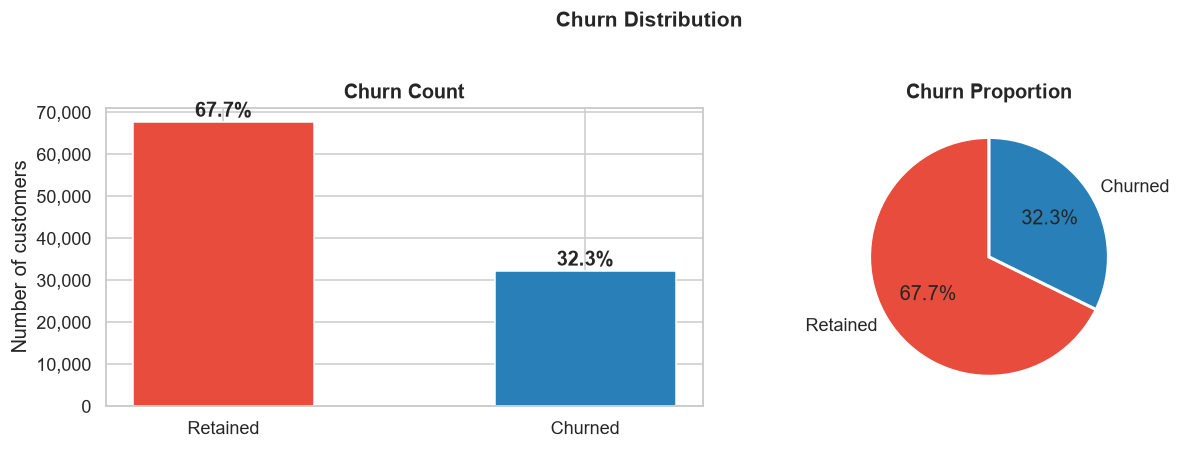

In [13]:
churn_counts = labels["churned"].value_counts()
churn_pct    = labels["churned"].value_counts(normalize=True) * 100

churn_summary = pd.DataFrame({"count": churn_counts, "percentage": churn_pct})
churn_summary.index = churn_summary.index.map({True: "Churned", False: "Retained"})
print(churn_summary.to_string())

colors = ["#e74c3c", "#2980b9"]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# bar chart
ax = axes[0]
bars = ax.bar(
    churn_summary.index, churn_summary["count"],
    color=colors, edgecolor="white", width=0.5,
)
for bar, pct in zip(bars, churn_summary["percentage"]):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 200,
        f"{pct:.1f}%",
        ha="center", va="bottom", fontweight="bold",
    )
ax.set_title("Churn Count", fontweight="bold")
ax.set_ylabel("Number of customers")
ax.yaxis.set_major_formatter(
    mticker.FuncFormatter(lambda x, _: f"{int(x):,}")
)

# pie chart
ax = axes[1]
ax.pie(
    churn_summary["count"],
    labels=churn_summary.index,
    autopct="%1.1f%%",
    colors=colors,
    startangle=90,
    wedgeprops=dict(edgecolor="white", linewidth=2),
)
ax.set_title("Churn Proportion", fontweight="bold")

plt.suptitle("Churn Distribution", y=1.02, fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

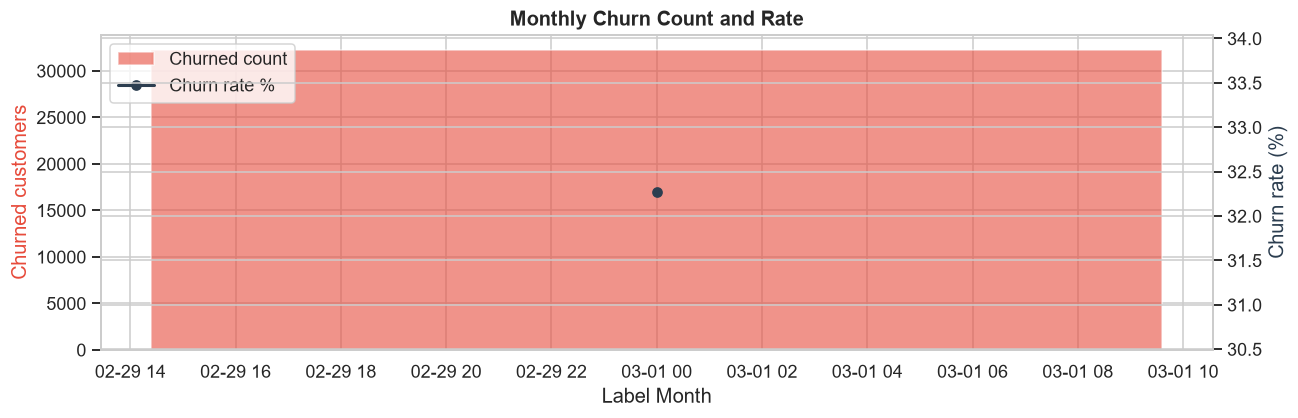

In [14]:
# Monthly churn count and rate
churn_time = (
    labels
    .groupby("label_month")["churned"]
    .agg(total="count", churned="sum")
    .assign(churn_rate=lambda d: d["churned"] / d["total"] * 100)
    .reset_index()
)

fig, ax1 = plt.subplots(figsize=(12, 4))
ax2 = ax1.twinx()

ax1.bar(
    churn_time["label_month"], churn_time["churned"],
    color="#e74c3c", alpha=0.6, label="Churned count",
)
ax2.plot(
    churn_time["label_month"], churn_time["churn_rate"],
    color="#2c3e50", marker="o", linewidth=2, label="Churn rate %",
)

ax1.set_xlabel("Label Month")
ax1.set_ylabel("Churned customers", color="#e74c3c")
ax2.set_ylabel("Churn rate (%)", color="#2c3e50")
ax1.set_title("Monthly Churn Count and Rate", fontweight="bold")

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc="upper left")

plt.tight_layout()
plt.show()

---
## 11 · Numerical Distributions

In [15]:
num_cols_cust = ["age", "tenure_months", "monthly_charges", "total_charges"]

customers[num_cols_cust].describe().T

,count,mean,std,min,25%,50%,75%,max
age,100000.0000,48.5260,17.8868,18.0000,33.0000,48.0000,64.0000,79.0000
tenure_months,100000.0000,36.0071,20.4870,1.0000,18.0000,36.0000,54.0000,71.0000
monthly_charges,100000.0000,69.9032,28.8695,20.0000,45.0000,69.9300,94.8500,120.0000
total_charges,100000.0000,2515.4438,1864.0566,20.0400,1018.0200,2073.6600,3688.3400,8509.3500


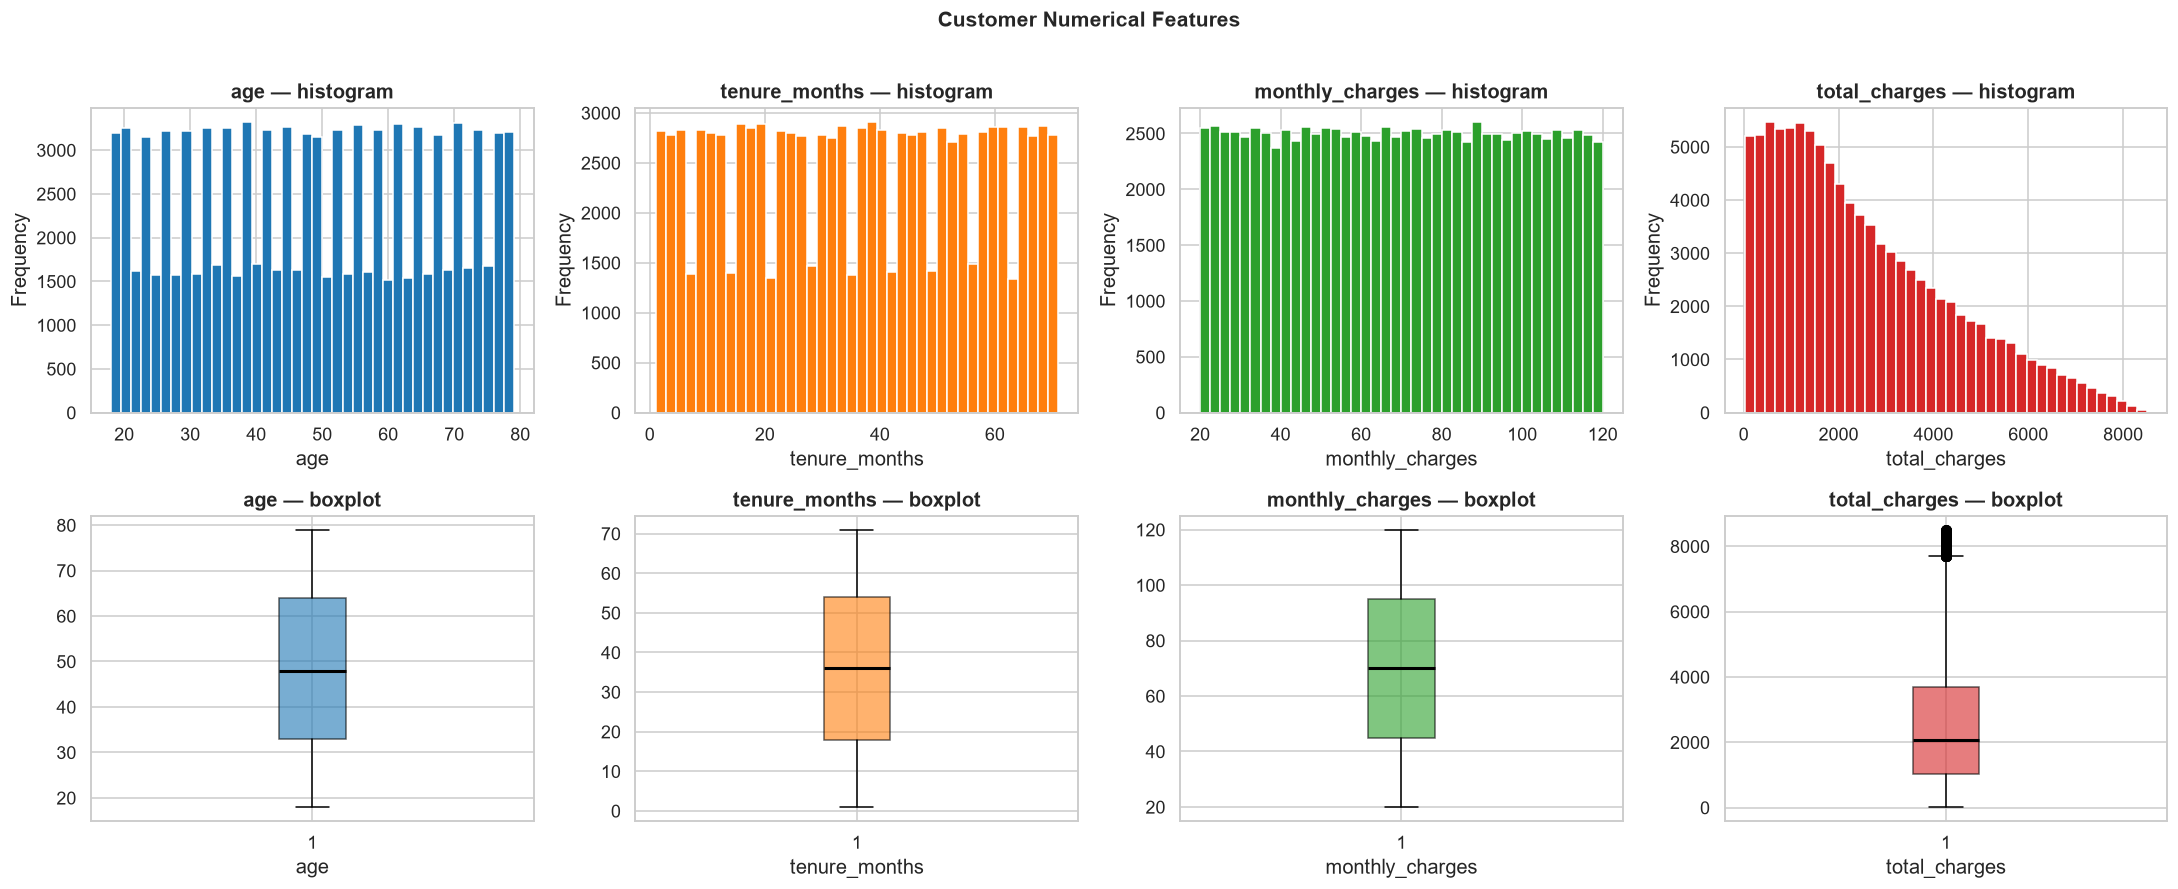

In [16]:
palette = sns.color_palette("tab10")
fig, axes = plt.subplots(2, 4, figsize=(20, 8))

for i, col in enumerate(num_cols_cust):
    ax_hist = axes[0, i]
    ax_hist.hist(customers[col].dropna(), bins=40, color=palette[i], edgecolor="white")
    ax_hist.set_title(f"{col} — histogram", fontweight="bold")
    ax_hist.set_xlabel(col)
    ax_hist.set_ylabel("Frequency")

    ax_box = axes[1, i]
    ax_box.boxplot(
        customers[col].dropna(),
        patch_artist=True,
        boxprops=dict(facecolor=palette[i], alpha=0.6),
        medianprops=dict(color="black", linewidth=2),
    )
    ax_box.set_title(f"{col} — boxplot", fontweight="bold")
    ax_box.set_xlabel(col)

plt.suptitle("Customer Numerical Features", y=1.01, fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

In [17]:
num_cols_txn  = ["amount"]
num_cols_supp = ["resolution_days", "sentiment_score"]

print("=== transactions — amount ===")
display(transactions[num_cols_txn].describe().T)

print("\n=== support_interactions ===")
display(support[num_cols_supp].describe().T)

=== transactions — amount ===


,count,mean,std,min,25%,50%,75%,max
amount,1000000.0000,74.9833,31.7591,20.0000,47.4500,75.0100,102.4700,130.0000



=== support_interactions ===


,count,mean,std,min,25%,50%,75%,max
resolution_days,500000.0000,7.5146,4.0292,1.0000,4.0000,8.0000,11.0000,14.0000
sentiment_score,500000.0000,-0.0006,0.5769,-1.0000,-0.5000,0.0000,0.4990,1.0000


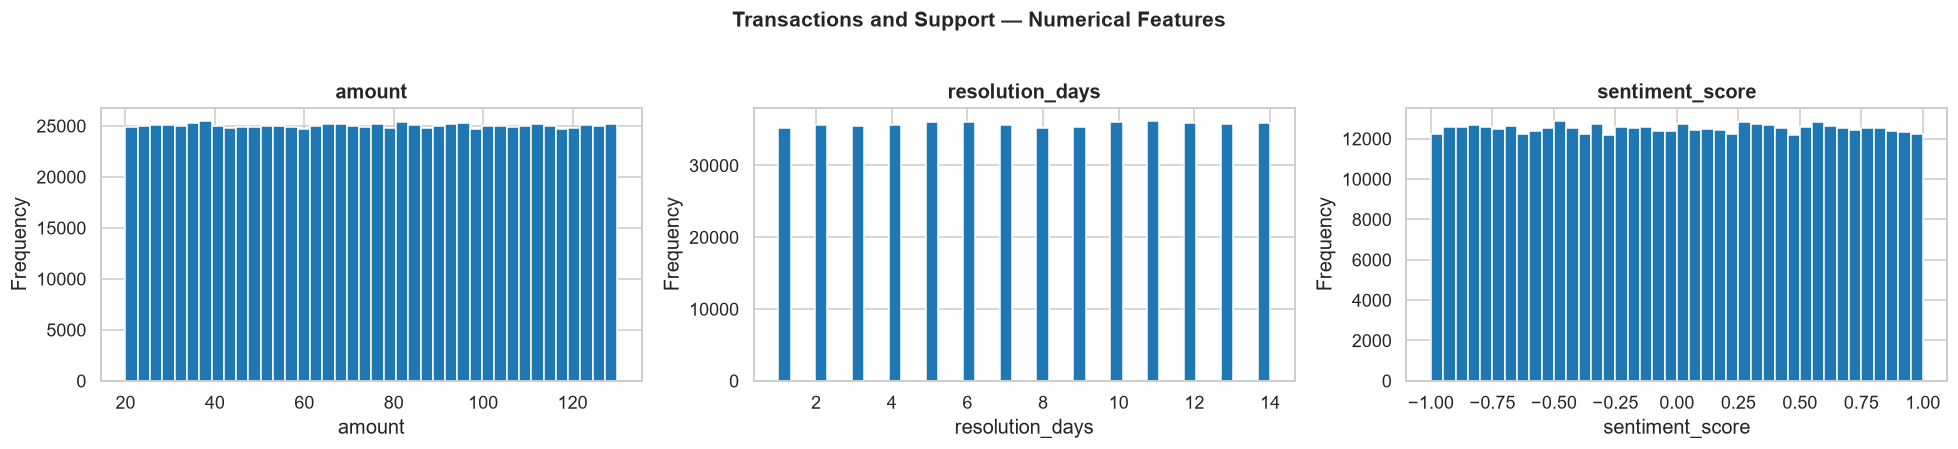

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4))

for ax, (df, col) in zip(
    axes,
    [
        (transactions, "amount"),
        (support,      "resolution_days"),
        (support,      "sentiment_score"),
    ],
):
    ax.hist(df[col].dropna(), bins=40, edgecolor="white")
    ax.set_title(col, fontweight="bold")
    ax.set_xlabel(col)
    ax.set_ylabel("Frequency")

plt.suptitle("Transactions and Support — Numerical Features", y=1.02, fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

---
## 12 · Categorical Distributions

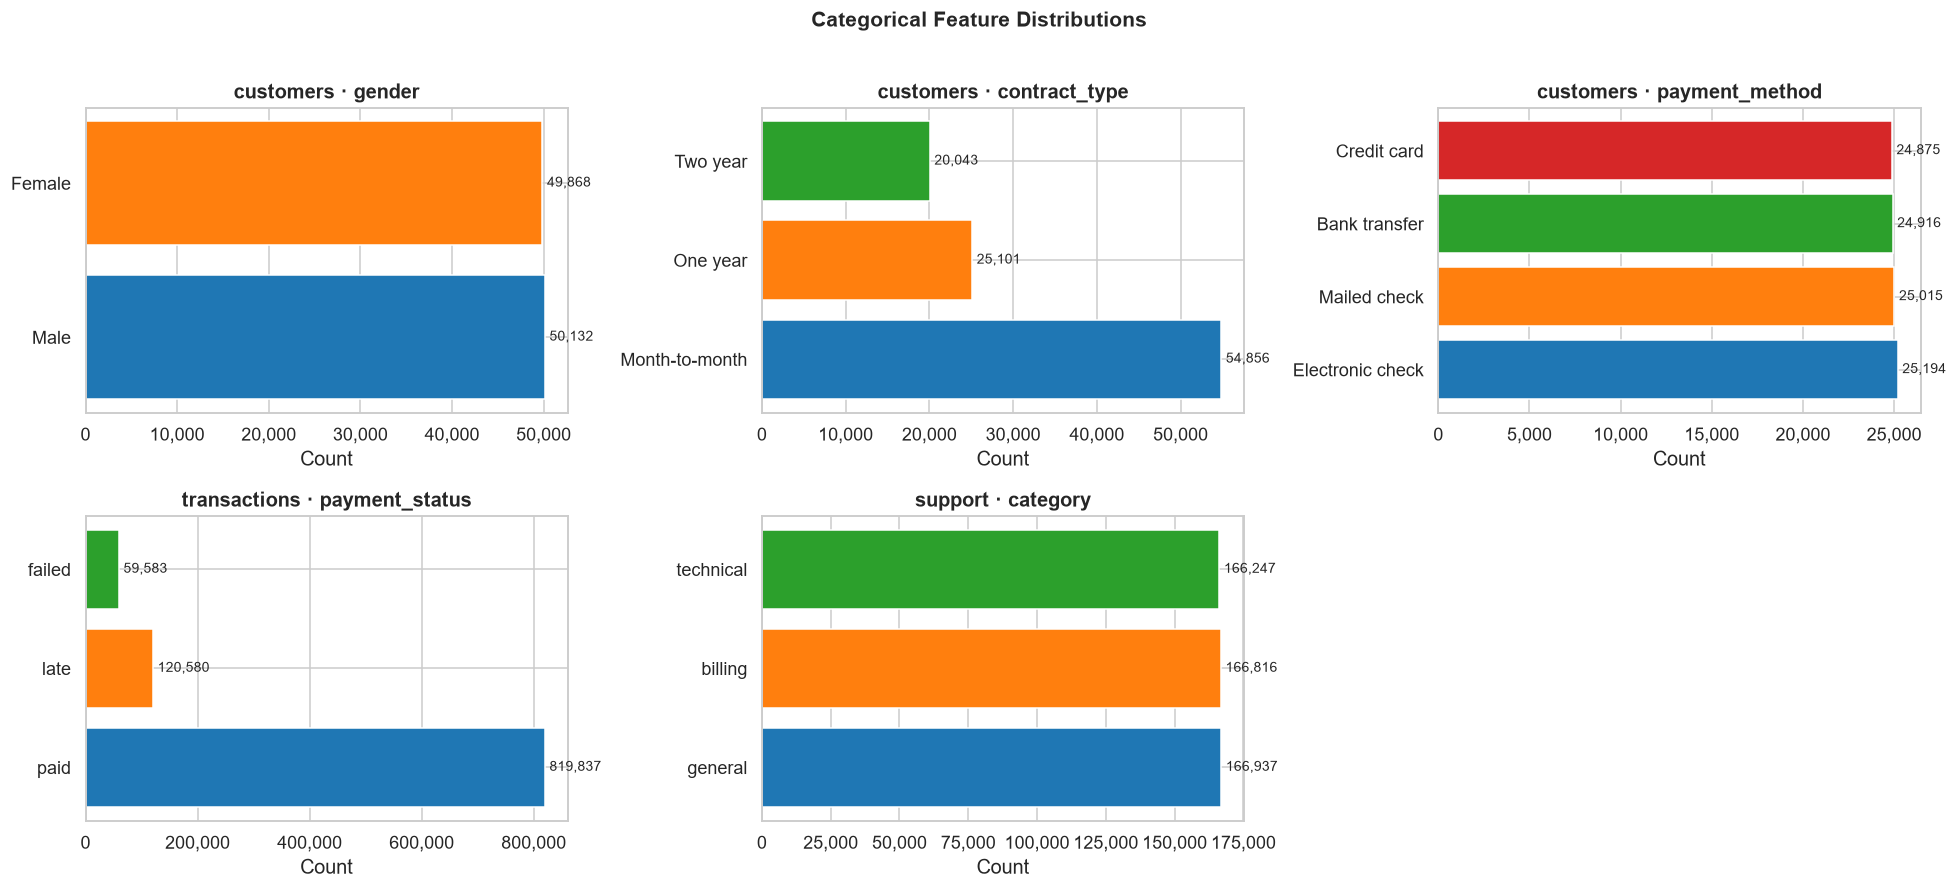

In [19]:
cat_cols_cust = ["gender", "contract_type", "payment_method"]
cat_cols_txn  = ["payment_status"]
cat_cols_supp = ["category"]

all_cat = (
    [(customers,    c, "customers")    for c in cat_cols_cust]
    + [(transactions, c, "transactions") for c in cat_cols_txn]
    + [(support,      c, "support")      for c in cat_cols_supp]
)

ncols = 3
nrows = -(-len(all_cat) // ncols)
fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * 6, nrows * 4))
axes = axes.flatten()
palette = sns.color_palette("tab10")

for ax, (df, col, src) in zip(axes, all_cat):
    counts = df[col].value_counts()
    bars = ax.barh(
        counts.index, counts.values,
        color=palette[: len(counts)], edgecolor="white",
    )
    for bar, val in zip(bars, counts.values):
        ax.text(
            bar.get_width() + counts.values.max() * 0.01,
            bar.get_y() + bar.get_height() / 2,
            f"{val:,}",
            va="center", fontsize=9,
        )
    ax.set_title(f"{src} · {col}", fontweight="bold")
    ax.set_xlabel("Count")
    ax.xaxis.set_major_formatter(
        mticker.FuncFormatter(lambda x, _: f"{int(x):,}")
    )

for ax in axes[len(all_cat):]:
    ax.set_visible(False)

plt.suptitle("Categorical Feature Distributions", y=1.01, fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

---
## 13 · Basic Relationships with Churn

In [20]:
# Use the most-recent label per customer
latest_labels = (
    labels
    .sort_values("label_month")
    .drop_duplicates("customer_id", keep="last")
    [["customer_id", "churned"]]
)

cust_churn = customers.merge(latest_labels, on="customer_id", how="inner")
print(f"Merged shape: {cust_churn.shape}")
cust_churn.head()

Merged shape: (100000, 9)


,customer_id,age,gender,tenure_months,contract_type,payment_method,monthly_charges,total_charges,churned
0,6e3d8adf-7f9d-4e34-bb6d-190576e545c5,56,Male,2,Month-to-month,Electronic check,28.4800,56.9600,True
1,740bfa1e-1d64-4ea2-9dab-6a475f51af39,69,Female,21,Month-to-month,Electronic check,110.3800,2317.9800,True
2,2804ba0f-7893-4f13-97be-b9411f0df4a8,46,Male,42,One year,Bank transfer,61.3100,2575.0200,False
3,b5986649-60d9-4470-8620-0ab0a2ae4b05,32,Female,22,Month-to-month,Bank transfer,89.6800,1972.9600,False
4,7fb45a3e-2e43-414a-85d0-060945ff51ba,60,Female,58,Month-to-month,Credit card,72.0100,4176.5800,True


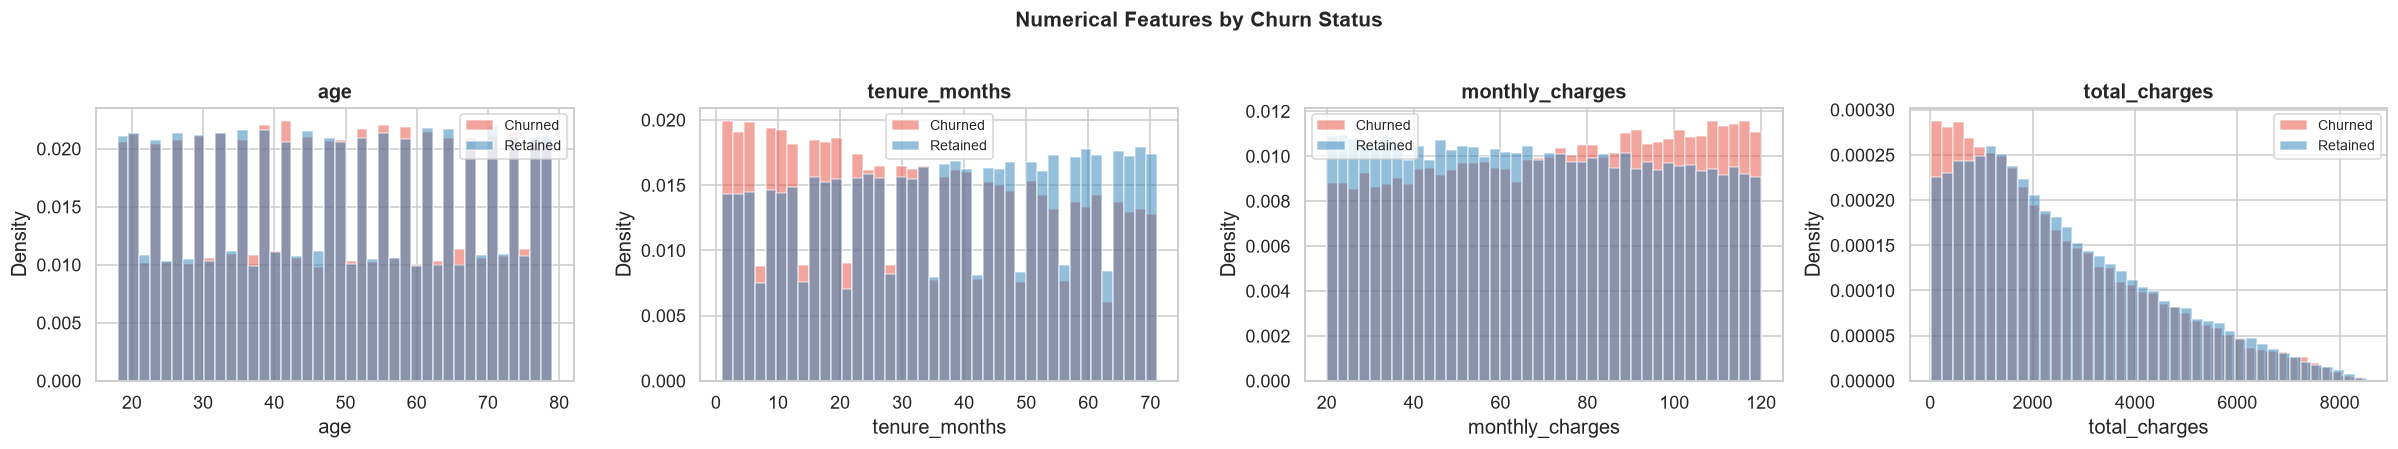

In [21]:
# Numerical features overlapping histograms
fig, axes = plt.subplots(1, 4, figsize=(22, 4))

for ax, col in zip(axes, num_cols_cust):
    for churned, color, label in [
        (True,  "#e74c3c", "Churned"),
        (False, "#2980b9", "Retained"),
    ]:
        subset = cust_churn.loc[cust_churn["churned"] == churned, col].dropna()
        ax.hist(subset, bins=40, alpha=0.5, color=color, label=label, density=True)
    ax.set_title(col, fontweight="bold")
    ax.set_xlabel(col)
    ax.set_ylabel("Density")
    ax.legend(fontsize=9)

plt.suptitle("Numerical Features by Churn Status", y=1.02, fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

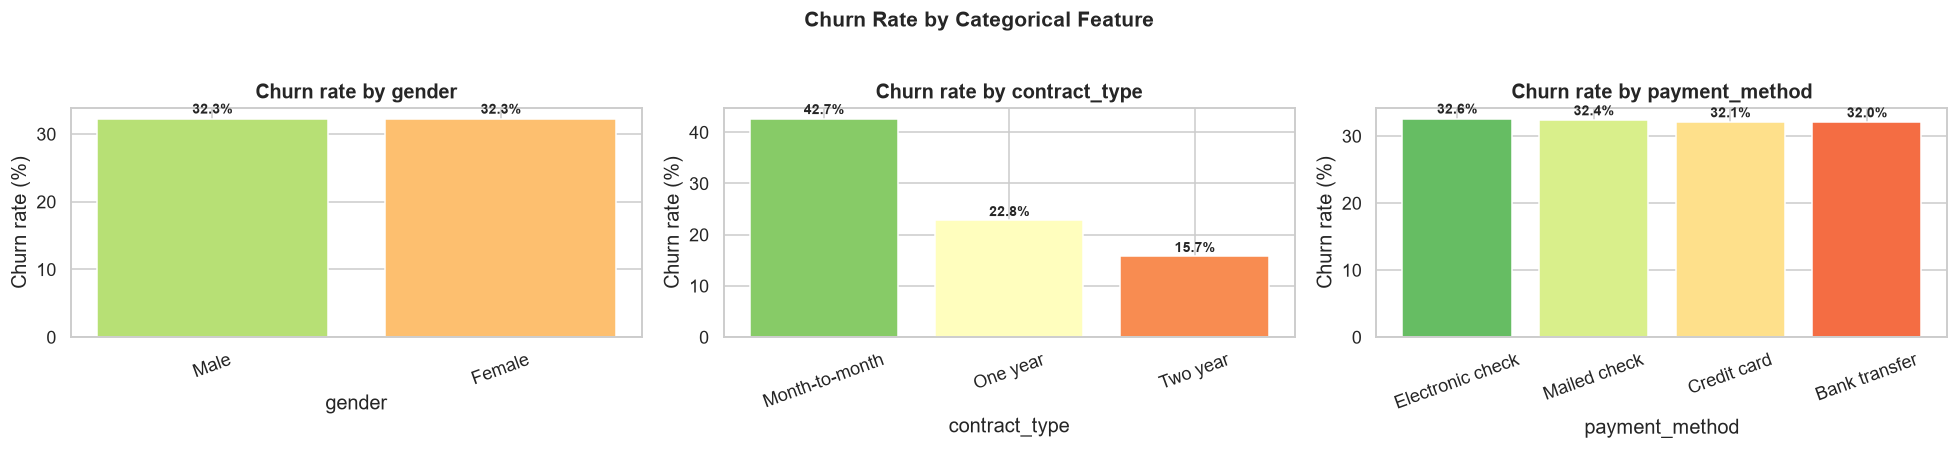

In [22]:
# Churn rate by categorical feature
fig, axes = plt.subplots(1, 3, figsize=(18, 4))

for ax, col in zip(axes, cat_cols_cust):
    churn_rate = (
        cust_churn
        .groupby(col)["churned"]
        .agg(total="count", churned="sum")
        .assign(churn_rate=lambda d: d["churned"] / d["total"] * 100)
        .sort_values("churn_rate", ascending=False)
    )
    n = len(churn_rate)
    bar_colors = sns.color_palette("RdYlGn_r", n)
    bars = ax.bar(
        churn_rate.index, churn_rate["churn_rate"],
        color=bar_colors, edgecolor="white",
    )
    for bar, val in zip(bars, churn_rate["churn_rate"]):
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 0.3,
            f"{val:.1f}%",
            ha="center", va="bottom", fontsize=9, fontweight="bold",
        )
    ax.set_title(f"Churn rate by {col}", fontweight="bold")
    ax.set_ylabel("Churn rate (%)")
    ax.set_xlabel(col)
    ax.tick_params(axis="x", rotation=20)

plt.suptitle("Churn Rate by Categorical Feature", y=1.02, fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

TypeError: Axes.boxplot() got an unexpected keyword argument 'labels'

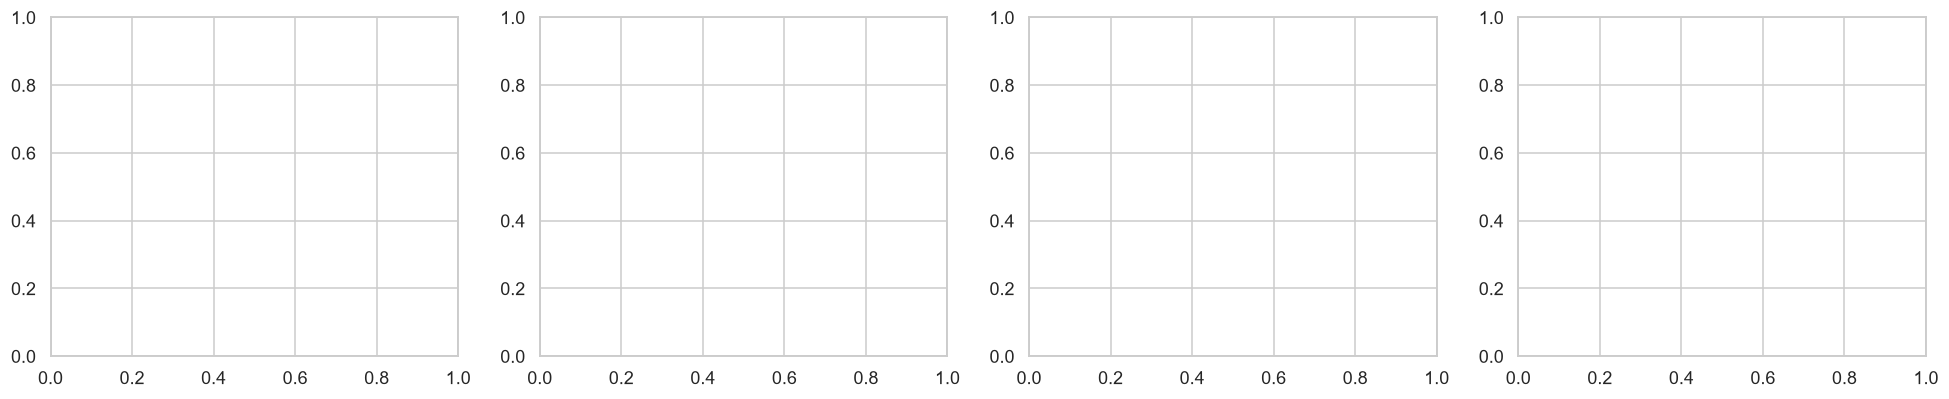

In [23]:
# Transaction aggregates per customer vs churn
txn_agg = (
    transactions
    .groupby("customer_id")
    .agg(
        txn_count=("transaction_id", "count"),
        txn_total_amount=("amount", "sum"),
        txn_avg_amount=("amount", "mean"),
        late_payment_rate=("payment_status", lambda x: (x == "late").mean()),
    )
    .reset_index()
)

txn_churn = txn_agg.merge(latest_labels, on="customer_id", how="inner")

txn_num_cols = ["txn_count", "txn_total_amount", "txn_avg_amount", "late_payment_rate"]

fig, axes = plt.subplots(1, 4, figsize=(22, 4))
for ax, col in zip(axes, txn_num_cols):
    retained = txn_churn.loc[txn_churn["churned"] == False, col]
    churned  = txn_churn.loc[txn_churn["churned"] == True,  col]
    ax.boxplot(
        [retained, churned],
        labels=["Retained", "Churned"],
        patch_artist=True,
        boxprops=dict(facecolor="#2980b9", alpha=0.6),
        medianprops=dict(color="black", linewidth=2),
    )
    ax.set_title(col, fontweight="bold")

plt.suptitle("Transaction Aggregates by Churn Status", y=1.02, fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

In [ ]:
# Support aggregates per customer vs churn
supp_agg = (
    support
    .groupby("customer_id")
    .agg(
        ticket_count=("interaction_id", "count"),
        avg_resolution_days=("resolution_days", "mean"),
        avg_sentiment=("sentiment_score", "mean"),
    )
    .reset_index()
)

supp_churn = supp_agg.merge(latest_labels, on="customer_id", how="inner")

supp_num_cols = ["ticket_count", "avg_resolution_days", "avg_sentiment"]

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, supp_num_cols):
    retained = supp_churn.loc[supp_churn["churned"] == False, col]
    churned  = supp_churn.loc[supp_churn["churned"] == True,  col]
    ax.boxplot(
        [retained, churned],
        labels=["Retained", "Churned"],
        patch_artist=True,
        boxprops=dict(facecolor="#27ae60", alpha=0.6),
        medianprops=dict(color="black", linewidth=2),
    )
    ax.set_title(col, fontweight="bold")

plt.suptitle("Support Aggregates by Churn Status", y=1.02, fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

In [ ]:
# Correlation heatmap — customer features + churn
corr_df = cust_churn[num_cols_cust + ["churned"]].copy()
corr_df["churned"] = corr_df["churned"].astype(int)

fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(
    corr_df.corr(),
    annot=True, fmt=".2f",
    cmap="coolwarm",
    vmin=-1, vmax=1,
    linewidths=0.5,
    ax=ax,
)
ax.set_title("Correlation Matrix — Customer Features + Churn", fontweight="bold")
plt.tight_layout()
plt.show()

---
## 14 · Conclusions

### Data Quality

| Finding | Detail |
|---------|--------|
| **No missing values** | All four datasets are fully populated. |
| **No duplicate primary keys** | Each dataset has unique IDs per row. |
| **Date columns parsed** | `transaction_date`, `ticket_date`, `label_month` are `datetime64`. |

### Churn Overview
- The label dataset spans multiple months; the overall churn rate and monthly trend are visible in Section 10.
- Class imbalance (if present) will need to be addressed during modelling (e.g. SMOTE, class-weight tuning).

### Key Signals (to be quantified in feature engineering)

| Feature | Preliminary Observation |
|---------|------------------------|
| `contract_type` | Month-to-month contracts likely have a higher churn rate — easiest to leave. |
| `tenure_months` | Shorter-tenure customers tend to churn more. |
| `monthly_charges` | Higher charges may correlate with higher churn risk. |
| `late_payment_rate` | Customers with frequent late payments may be at higher risk. |
| `avg_sentiment` | Lower sentiment scores in support tickets signal dissatisfied customers. |
| `ticket_count` | High ticket volume can be a churn precursor. |

### Next Steps
1. **`02_feature_engineering.ipynb`** — aggregate transaction and support features per customer per month; encode categoricals; create time-windowed features.
2. **`03_modelling.ipynb`** — train baseline (logistic regression) and advanced models (XGBoost, LightGBM) with proper temporal cross-validation.
3. **`04_evaluation.ipynb`** — ROC-AUC, precision-recall curves, calibration plots, and SHAP explanations.

In [1]:
df = load_features_from_snowflake()

print("Shape:", df.shape)
print("Unique customers:", df["CUSTOMER_ID"].nunique())
print("Null values:")
print(df.isnull().sum())

NameError: name 'load_features_from_snowflake' is not defined